In [2]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np

In [3]:
df = pd.read_csv('../dataset/Instagram visits clustering.csv')
df.head()

,User ID,Instagram visit score,Spending_rank(0 to 100)
0,0,63,24.050708
1,1,61,25.223290
2,2,104,18.528245
3,3,82,86.890232
4,4,14,31.492397


In [4]:
df.info()
df.describe()
df.size

<class 'pandas.DataFrame'>
RangeIndex: 2600 entries, 0 to 2599
Data columns (total 3 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   User ID                  2600 non-null   int64  
 1   Instagram visit score    2600 non-null   int64  
 2   Spending_rank(0 to 100)  2600 non-null   float64
dtypes: float64(1), int64(2)
memory usage: 61.1 KB


7800


Pada dataset ini semua tipe data adalah numerik, dengan 3 kolo bertipe int dan 1 kolo bertipe float. Dataset ini memilliki 3 kolom dan 2600 baris dan memiliki frame size 7800. 

In [5]:
na = pd.DataFrame({"na": df.isna().sum()})
na

,na
User ID,0
Instagram visit score,0
Spending_rank(0 to 100),0


In [6]:
df.duplicated().sum()

np.int64(0)

Pada dataset ini datanya termasuk kedalam kategori yang bersih karena tidak ada duplicate dan missing value.

In [7]:
df_clean = df.copy()
df_clean.drop(columns=['User ID'], inplace=True)
df_clean.head()

,Instagram visit score,Spending_rank(0 to 100)
0,63,24.050708
1,61,25.223290
2,104,18.528245
3,82,86.890232
4,14,31.492397


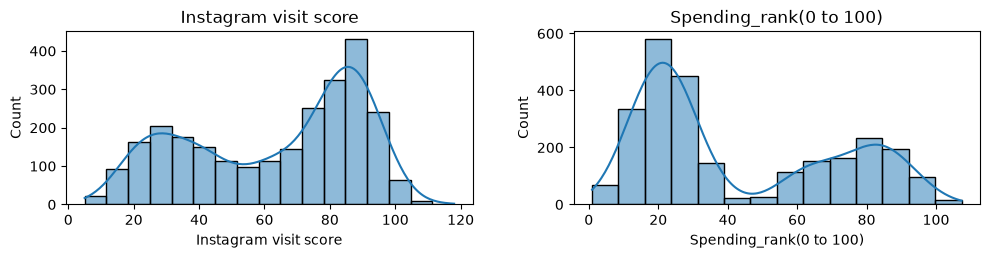

In [8]:
cols = df_clean.select_dtypes('number')

plt.figure(figsize=(10, 10))

for i, col in enumerate(cols):
    plt.subplot(4, 2, i+1)
    sns.histplot(df_clean[col], kde=True)
    plt.title(col)

plt.tight_layout(w_pad=3, h_pad=3)
plt.show()

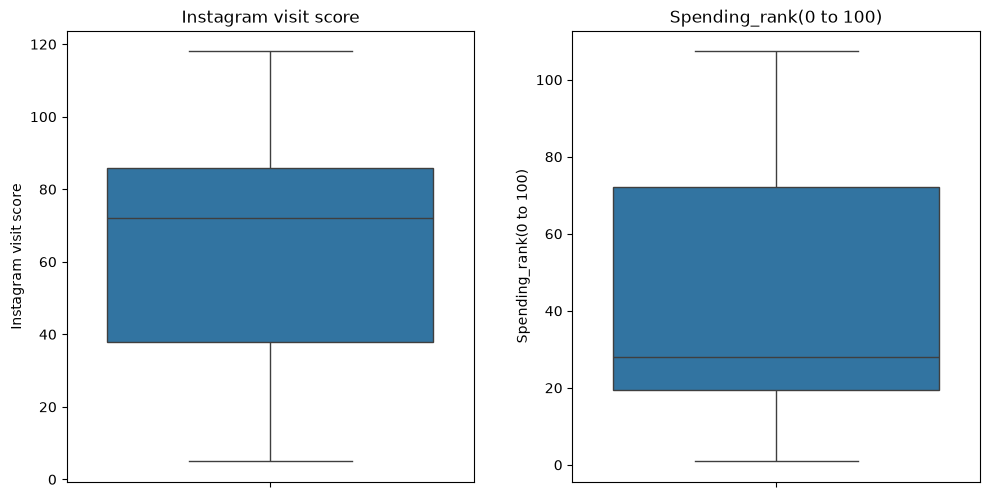

In [9]:
cols = df_clean.select_dtypes('number')

plt.figure(figsize=(10, 20))

for i, col in enumerate(cols):
    plt.subplot(4, 2, i+1)
    sns.boxplot(df_clean[col])
    plt.title(col)

plt.tight_layout(w_pad=3, h_pad=3)
plt.show()

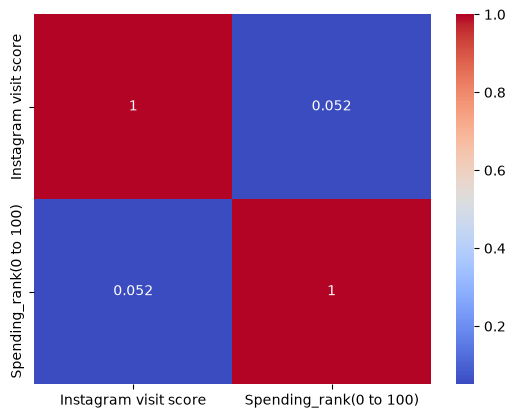

In [10]:
sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm')
plt.show()

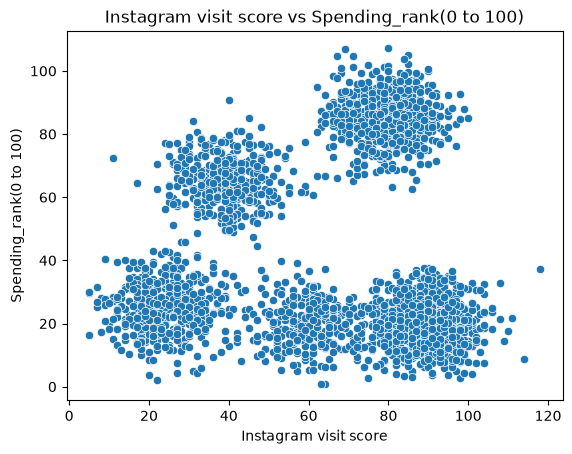

In [11]:
sns.scatterplot(x='Instagram visit score', y='Spending_rank(0 to 100)', data=df_clean)
plt.title('Instagram visit score vs Spending_rank(0 to 100)')
plt.show()


In [16]:

q1 = df_clean.quantile(0.25)
q3 = df_clean.quantile(0.75)

iqr = q3 - q1 

bb = q1 - 1.5 * iqr
bt = q3 + 1.5 * iqr

outlier = ((df_clean < bb) | (df_clean > bt)).sum()

outlier = pd.DataFrame({'outlier': outlier, 'persentase': outlier / len(df_clean)})
outlier

,outlier,persentase
Instagram visit score,0,0.0
Spending_rank(0 to 100),0,0.0
